# Kunci Lab 01: regresi linear dan prediksi

File ini berisi solusi latihan Lab 01. Semua angka di sini dihasilkan dari
data di folder `data/`, jadi hasil Anda harus sama (atau sangat dekat).



<!-- alur_belajar -->

**Kaitan dengan materi lain**

| Bekal sebelumnya | Fokus notebook ini | Hasil yang dibawa berikutnya |
|---|---|---|
| Sesi 00: membaca tabel dan pola pada grafik. | Susun X dan y, latih regresi linear, baca koefisien, dan bandingkan aktual dengan prediksi. | Pola residual dan hubungan melengkung mengantar pemilihan bentuk pada Sesi 02. |

## Persiapan: alamat data

Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**.



**Alur sesi:** kita menghubungkan fitur dengan target melalui regresi. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah perbedaan titik aktual, hasil model, dan residual.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")

Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import numpy as np

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})

## 1. Latihan: produktivitas padi



<!-- kamus_variabel:produktivitas_padi.csv -->

### Kenali data: Produktivitas padi

**Data:** `data/produktivitas_padi.csv`. **Satu baris:** satu wilayah pertanian pada contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Y_Produktivitas_Padi` | Hasil panen padi per luas lahan. | Produktivitas per hektar; skala massa tidak dirinci sumber | Y: target |
| `X1_Jumlah_Pupuk` | Banyaknya pupuk yang digunakan pada pertanian. | Jumlah pupuk; satuan/cakupan luas tidak dirinci | X: penjelas |
| `X2_Curah_Hujan` | Banyaknya hujan pada wilayah pertanian. | Satuan/periode tidak dirinci sumber | X: penjelas |
| `X3_Sinar_Matahari` | Lama penyinaran matahari yang diterima lahan. | Jam; periode akumulasi tidak dirinci | X: penjelas |

Sumber menyebut produktivitas per hektar, tetapi tidak merinci semua skala. Interpretasi dalam ton, kg, atau mm memerlukan konfirmasi metadata, bukan hanya dugaan dari angka.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `pd.read_csv` | Membaca CSV atau TSV menjadi tabel. | Alamat berkas; sep="\t" memilih pemisah tab pada TSV. | DataFrame; periksa nama kolom dan ukuran sebelum analisis. |
| `head` | Melihat contoh isi tabel. | Tanpa angka menampilkan lima baris; head(10) menampilkan sepuluh. | Cuplikan awal, bukan ringkasan seluruh data. |
| `dropna` | Membentuk sampel dengan kolom yang dibutuhkan terisi. | Pilih kolom model dahulu, lalu dropna(); subset membatasi kolom pemeriksaan. | Tabel baru; baris terbuang dapat mengubah komposisi sampel. |
| `rename` | Memperjelas nama kolom tanpa mengganti angka. | columns berisi pasangan nama lama dan nama baru. | Tabel dengan nama kolom baru; simpan kembali bila ingin dipakai sel berikutnya. |
| `LinearRegression` | Menyiapkan regresi linear dengan scikit-learn. | fit_intercept=True adalah bawaan; X tabel dua dimensi, y satu target. | Estimator yang belum dilatih; koefisien baru tersedia setelah fit. |
| `fit` | Mengestimasi parameter model. | scikit-learn: fit(X_train, y_train); paket statistik: fit() sesudah model menerima data. | Parameter dipelajari dari sampel yang diberikan; data uji tidak dipakai untuk melatih. |
| `predict` | Menghitung prediksi dari model yang sudah dilatih. | Tabel X baru dengan nama dan urutan fitur seperti saat fit. | Satu prediksi tiap baris; ketepatan pada data uji tetap harus diukur. |
| `sm.add_constant` | Menambahkan kolom intersep untuk pelengkap statistik. | X yang sama; has_constant="add" meminta kolom konstan. | Matriks X uji; scikit-learn sudah menghitung intersep sendiri sehingga tidak perlu kolom ini. |
| `sm.OLS` | Menghitung standard error dan pengujian regresi linear. | Urutan OLS(y, X_uji), lalu fit(); X_uji mencakup intersep. | Hasil inferensi pada sampel yang sama; model prediksi utama tetap scikit-learn. |
| `summary, pvalues, dan bse` | Membaca ringkasan hasil statistik. | Objek hasil fit; bse adalah standard error dan pvalues adalah p-value. | Nilai p menguji hipotesis sesuai asumsi, bukan ukuran besarnya dampak atau bukti kausalitas. |
| `subplots, scatter, dan plot` | Membuat ruang grafik lalu menampilkan hubungan atau pola waktu. | figsize ukuran; scatter untuk titik, plot untuk garis; sumbu dan satuan diberi label. | Titik menunjukkan pengamatan; garis mengikuti urutan X sehingga data perlu diurutkan bila perlu. |
| `axhline dan axvline` | Memberi patokan pada grafik. | y untuk garis horizontal, x untuk garis vertikal; linestyle mengatur pola garis. | Contoh: residual nol, periode program, atau batas latihan/uji; bukan hasil estimasi tambahan. |

In [3]:
padi = pd.read_csv(URL_DATA + "produktivitas_padi.csv")

padi.head()

,Y_Produktivitas_Padi,X1_Jumlah_Pupuk,X2_Curah_Hujan,X3_Sinar_Matahari
0,7.5,155,1850,220
1,6.8,120,1600,205
2,8.2,200,2100,240
3,8.5,225,2200,255
4,6.2,100,1500,190


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [4]:
sampel_model_padi = padi[
    ["Y_Produktivitas_Padi", "X1_Jumlah_Pupuk", "X2_Curah_Hujan", "X3_Sinar_Matahari"]
].dropna()
X_model_padi = sampel_model_padi[
    ["X1_Jumlah_Pupuk", "X2_Curah_Hujan", "X3_Sinar_Matahari"]
]
y_model_padi = sampel_model_padi["Y_Produktivitas_Padi"]

In [5]:
model_padi = LinearRegression()
model_padi.fit(X_model_padi, y_model_padi)

LinearRegression()

### Lihat hasil model: Produktivitas padi (skala data)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

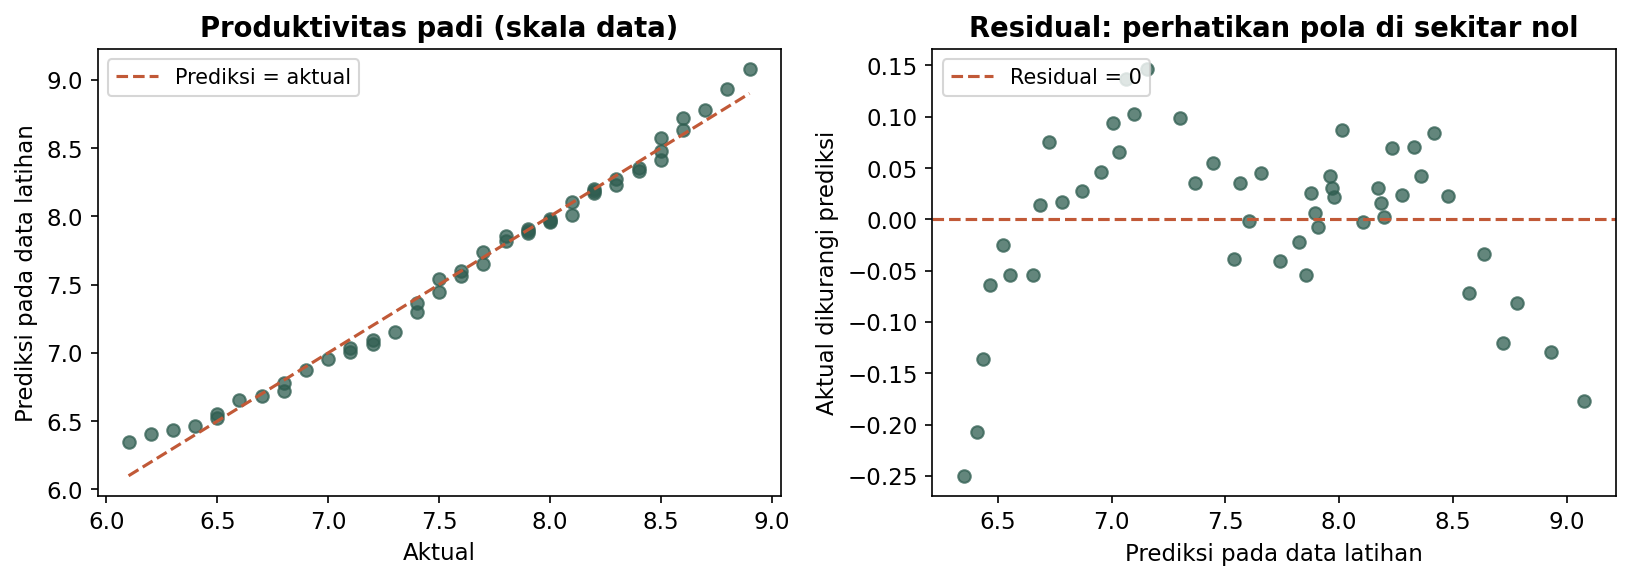

In [6]:
prediksi_visual = model_padi.predict(X_model_padi)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_padi, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_padi.min(), y_model_padi.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Produktivitas padi (skala data)")
axes[1].scatter(prediksi_visual, y_model_padi - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [7]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
X_uji_model_padi = sm.add_constant(X_model_padi, has_constant="add")
X_uji_model_padi = X_uji_model_padi.rename(columns={"const": "Intercept"})
uji_model_padi = sm.OLS(y_model_padi, X_uji_model_padi).fit()
print(uji_model_padi.summary())

                             OLS Regression Results                             
Dep. Variable:     Y_Produktivitas_Padi   R-squared:                       0.988
Model:                              OLS   Adj. R-squared:                  0.987
Method:                   Least Squares   F-statistic:                     1256.
Date:                  Sun, 25 Oct 2026   Prob (F-statistic):           4.03e-44
Time:                          23:44:31   Log-Likelihood:                 53.903
No. Observations:                    50   AIC:                            -99.81
Df Residuals:                        46   BIC:                            -92.16
Df Model:                             3                                         
Covariance Type:              nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         

Kesimpulan:

- Yang signifikan hanya curah hujan (p = 0,0000, koefisien 0,0029).
  Kenaikan curah hujan 100 mm menaikkan produktivitas sekitar 0,29 ton.
- Pupuk (p = 0,69) dan sinar matahari (p = 0,48) tidak signifikan.
- R kuadrat 0,988, tapi lihat catatan: data simulasi.



In [8]:
print(uji_model_padi.pvalues.round(4))

Intercept            0.1827
X1_Jumlah_Pupuk      0.6938
X2_Curah_Hujan       0.0000
X3_Sinar_Matahari    0.4768
dtype: float64


## 2. Latihan: angka harapan hidup



<!-- kamus_variabel:harapan_hidup.csv -->

### Kenali data: Angka harapan hidup

**Data:** `data/harapan_hidup.csv`. **Satu baris:** satu negara pada contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Y_Angka_Harapan_Hidup` | Rata-rata lama hidup yang diharapkan menurut indikator pada contoh. | Tahun | Y: target |
| `X1_Pengeluaran_Kesehatan` | Pengeluaran kesehatan per penduduk (per kapita). | Uang per kapita; mata uang/periode tidak dirinci | X: penjelas |
| `X2_Tingkat_Imunisasi` | Persentase anak yang memperoleh imunisasi. | Persen; jenis imunisasi tidak dirinci | X: penjelas |
| `X3_Konsumsi_Kalori` | Rata-rata konsumsi energi makanan per hari. | Kalori harian; rincian satuan energi mengikuti sumber | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `pd.Series` | Menyusun satu kolom bernama atau koefisien berlabel. | Nilai dan index sebagai label; name memberi nama kolom. | Series; label membantu mencocokkan koefisien, prediksi, dan baris asal. |
| `loc dan iloc` | Memilih baris atau kolom secara jelas. | loc memakai label atau kondisi; iloc memakai posisi mulai 0; dua titik berarti seluruh rentang. | Bagian tabel; pertahankan indeks agar y dan prediksi sejajar. |
| `coef_ dan intercept_` | Membaca kemiringan dan intersep model scikit-learn. | Atribut tanpa tanda kurung; urutan coef_ mengikuti kolom X. | Linear: perubahan prediksi y per satu unit X, dengan fitur lain tetap; logit memakai skala log-odds. |

In [9]:
harapan = pd.read_csv(URL_DATA + "harapan_hidup.csv")

harapan.head()

,Y_Angka_Harapan_Hidup,X1_Pengeluaran_Kesehatan,X2_Tingkat_Imunisasi,X3_Konsumsi_Kalori
0,75.5,1550,92,2850
1,72.1,850,85,2600
2,81.2,4500,98,3300
3,82.5,5500,99,3450
4,68.5,350,75,2300


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [10]:
sampel_model_harapan = harapan[
    [
        "Y_Angka_Harapan_Hidup",
        "X1_Pengeluaran_Kesehatan",
        "X2_Tingkat_Imunisasi",
        "X3_Konsumsi_Kalori",
    ]
].dropna()
X_model_harapan = sampel_model_harapan[
    ["X1_Pengeluaran_Kesehatan", "X2_Tingkat_Imunisasi", "X3_Konsumsi_Kalori"]
]
y_model_harapan = sampel_model_harapan["Y_Angka_Harapan_Hidup"]

In [11]:
model_harapan = LinearRegression()
model_harapan.fit(X_model_harapan, y_model_harapan)

koefisien_model_harapan = pd.Series(model_harapan.coef_, index=X_model_harapan.columns)
koefisien_model_harapan.loc["Intercept"] = model_harapan.intercept_

### Lihat hasil model: Harapan hidup (tahun)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

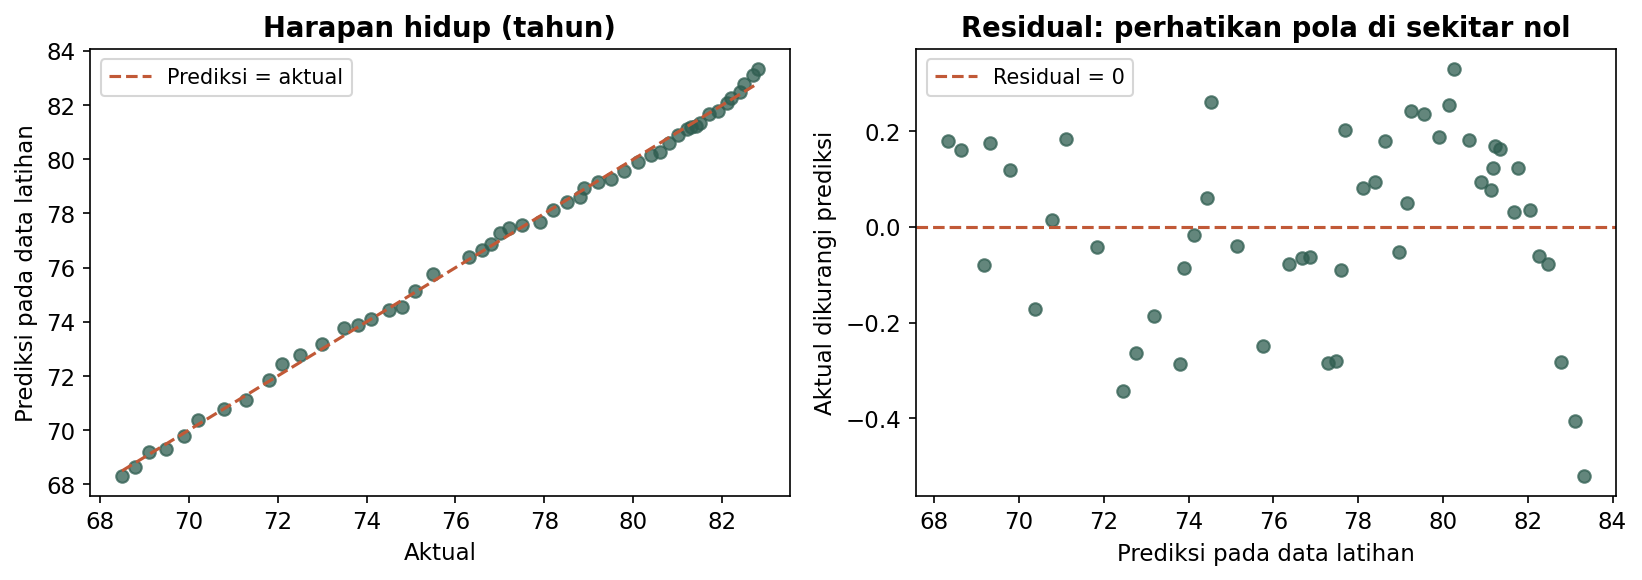

In [12]:
prediksi_visual = model_harapan.predict(X_model_harapan)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_harapan, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_harapan.min(), y_model_harapan.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Harapan hidup (tahun)")
axes[1].scatter(prediksi_visual, y_model_harapan - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [13]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
X_uji_model_harapan = sm.add_constant(X_model_harapan, has_constant="add")
X_uji_model_harapan = X_uji_model_harapan.rename(columns={"const": "Intercept"})
uji_model_harapan = sm.OLS(y_model_harapan, X_uji_model_harapan).fit()
print(koefisien_model_harapan.round(4))
print(uji_model_harapan.pvalues.round(4))

X1_Pengeluaran_Kesehatan     0.0002
X2_Tingkat_Imunisasi         0.1335
X3_Konsumsi_Kalori           0.0090
Intercept                   37.5539
dtype: float64
Intercept                   0.0000
X1_Pengeluaran_Kesehatan    0.2346
X2_Tingkat_Imunisasi        0.0018
X3_Konsumsi_Kalori          0.0000
dtype: float64


Yang signifikan: tingkat imunisasi (0,1335; p = 0,0018) dan konsumsi
kalori (0,0090; p = 0,0000). Pengeluaran kesehatan tidak signifikan
(p = 0,23) setelah dua variabel lain dikontrol.



## 3. Latihan: prediksi



<!-- panduan_perintah -->

**Perintah pada tahap ini.** Baca kegunaan dan masukan sebelum menjalankan contoh. Fungsi yang sudah dijelaskan tidak diulang pada setiap sel.

| Perintah | Untuk apa? | Arti masukan atau argumen | Hasil dan cara membacanya |
|---|---|---|---|
| `pd.DataFrame` | Menyusun beberapa kolom menjadi tabel. | Dictionary: nama kolom di kiri, daftar nilai di kanan; panjang daftar harus sama. | DataFrame; satu baris mempunyai arti sesuai unit pengamatan kasus. |

In [14]:
situasi = pd.DataFrame({
    "X1_Jumlah_Pupuk": [200],
    "X2_Curah_Hujan": [1500],
    "X3_Sinar_Matahari": [200],
})
prediksi_padi_baru = model_padi.predict(situasi)
print("Prediksi produktivitas:", round(prediksi_padi_baru[0], 3))

Prediksi produktivitas: 6.265


### Pengayaan: ulangi prediksi pada contoh penjualan

Bagian ini mengulang contoh terbimbing Lab 01 dengan `penjualan_produk.csv`. Gunakan model dan satuan penjualan, terpisah dari prediksi padi di atas.

<!-- kamus_variabel:penjualan_produk.csv -->

### Kenali data: Penjualan produk

**Data:** `data/penjualan_produk.csv`. **Satu baris:** satu pengamatan penjualan produk dalam contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Y_Penjualan_Unit` | Banyaknya produk yang terjual. | Unit produk dalam data simulasi | Y: target |
| `X1_Biaya_Iklan` | Biaya promosi/iklan untuk produk tersebut. | Uang; skala tidak dirinci | X: penjelas |
| `X2_Harga_Produk` | Harga jual produk milik perusahaan. | Uang per unit; skala tidak dirinci | X: penjelas |
| `X3_Harga_Kompetitor` | Harga produk pesaing yang menjadi pembanding. | Uang per unit; skala tidak dirinci | X: penjelas |

Harga produk sendiri dan harga kompetitor adalah dua variabel berbeda. Periode penjualan dan skala mata uang tidak dijelaskan pada sumber.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [15]:
jual = pd.read_csv(URL_DATA + "penjualan_produk.csv")
jual.head()

,Y_Penjualan_Unit,X1_Biaya_Iklan,X2_Harga_Produk,X3_Harga_Kompetitor
0,150.5,50.2,99.9,105.1
1,145.2,45.8,102.5,103.2
2,180.9,75.1,95.5,110.5
3,135.8,40.5,105.0,99.8
4,165.3,60.9,98.0,108.3


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [16]:
sampel_model_jual = jual[
    ["Y_Penjualan_Unit", "X1_Biaya_Iklan", "X2_Harga_Produk", "X3_Harga_Kompetitor"]
].dropna()
X_model_jual = sampel_model_jual[
    ["X1_Biaya_Iklan", "X2_Harga_Produk", "X3_Harga_Kompetitor"]
]
y_model_jual = sampel_model_jual["Y_Penjualan_Unit"]

In [17]:
model_jual = LinearRegression()
model_jual.fit(X_model_jual, y_model_jual)
situasi_jual = pd.DataFrame(
    {"X1_Biaya_Iklan": [60], "X2_Harga_Produk": [100], "X3_Harga_Kompetitor": [105]}
)
prediksi_penjualan_baru = model_jual.predict(situasi_jual)
print("Prediksi penjualan:", round(prediksi_penjualan_baru[0], 2))

Prediksi penjualan: 159.22


### Lihat hasil model: Penjualan (unit)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

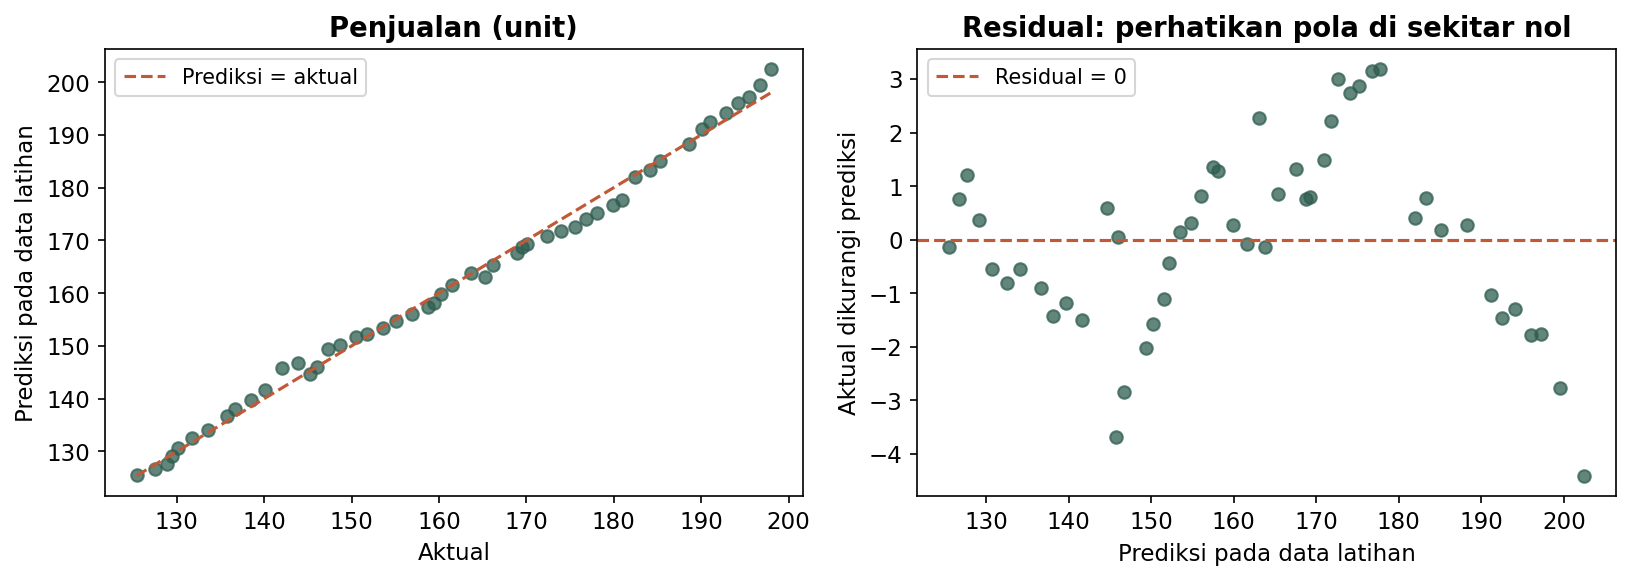

In [18]:
prediksi_visual = model_jual.predict(X_model_jual)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_jual, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_jual.min(), y_model_jual.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Penjualan (unit)")
axes[1].scatter(prediksi_visual, y_model_jual - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

## Selanjutnya

Kembali ke [Lab 01](https://colab.research.google.com/github/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/materi/02_latihan/01_regresi_dasar.ipynb) dan cocokkan langkah serta interpretasinya. Gunakan [panduan pengajar](https://github.com/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/pengajar/README.md#pembahasan-latihan) untuk pembahasan bersama.